<h3>Implement and run Quantum Fourier Transforms and Shor’s algorithm </h3>

Quantum Fourier Transform Circuit:


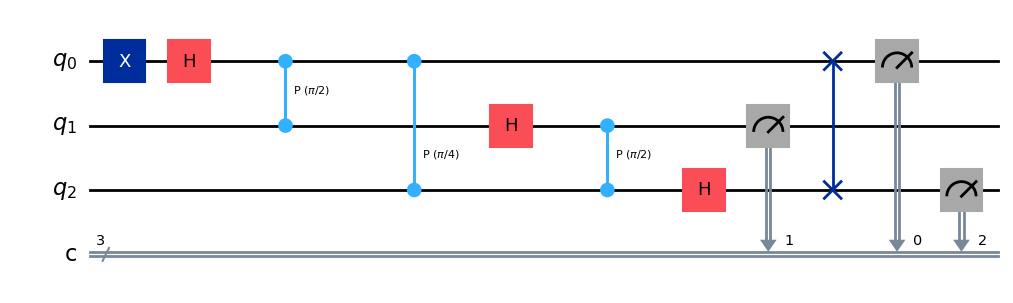


Measurement counts:
{'101': 138, '110': 123, '010': 125, '001': 130, '100': 134, '111': 124, '011': 123, '000': 127}


In [3]:
# Quantum Fourier Transform

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from math import pi

# Create a 3-qubit QFT circuit
n = 3
qc = QuantumCircuit(n, n)

# Prepare the input state |001>
qc.x(0)

# Apply QFT gates
for j in range(n):
    qc.h(j)
    for k in range(j + 1, n):
        qc.cp(pi / (2 ** (k - j)), k, j)

# Reverse qubit order
for j in range(n // 2):
    qc.swap(j, n - j - 1)

# Measure all qubits
qc.measure(range(n), range(n))

print("Quantum Fourier Transform Circuit:")
display(qc.draw("mpl"))

# Run on quantum simulator
simulator = AerSimulator()
# compiled = transpile(qc, simulator)
result = simulator.run(
    qc, shots=1024
).result()

counts = result.get_counts()
print("\nMeasurement counts:")
print(counts)


In [4]:
# Shor’s algorithm

from math import gcd

def shor_demo(N, a):
    print("Number to factor:", N)
    print("Selected base:", a)

    # Step 1: Check whether a and N share a factor
    g = gcd(a, N)

    if g > 1:
        print("Factor found directly:", g, N // g)
        return

    # Step 2: Find the order r classically
    r = 1
    value = a % N

    while value != 1:
        value = (value * a) % N
        r += 1

    print("Order r =", r)

    # Step 3: Check whether r is even
    if r % 2 != 0:
        print("Odd order. Choose another base.")
        return

    x = pow(a, r // 2, N)

    # Step 4: Check for a trivial result
    if x == 1 or x == N - 1:
        print("This base does not yield factors.")
        return

    # Step 5: Calculate non-trivial factors
    p = gcd(x - 1, N)
    q = gcd(x + 1, N)

    if p * q == N and p > 1 and q > 1:
        print("Factors:", p, "and", q)
    else:
        print("Try a different base.")

# Demonstration: factor 15 using base 2
shor_demo(15, 2)


Number to factor: 15
Selected base: 2
Order r = 4
Factors: 3 and 5
